# IT5022 — Fundamentals of Machine Learning
## Notebook 04: Unsupervised Learning — Customer Risk Segmentation
**Project:** Real-World Credit Risk Scoring & Customer Financial Segmentation  
**Authors:** MSc Candidate Ginuka (MS26922898) 

---

### Objectives of this Notebook:
1. **Unlabelled Pattern Discovery:** Remove the `Credit_Score` target variable to discover natural customer financial segments.
2. **Algorithm 1 (Centroid-based Partitioning):** K-Means Clustering:
   - Within-Cluster Sum of Squares (Inertia/Elbow method) for $K \in [2, 8]$.
   - Silhouette Coefficient analysis ($[-1, +1]$) across cluster candidates.
   - Cluster persona profiling: de-scale cluster centers back to raw financial metrics.
3. **Algorithm 2 (Density-based Spatial Clustering):** DBSCAN:
   - Optimize $\epsilon$ using $k$-distance nearest-neighbor plots.
   - Detect dense financial clusters and isolate financial anomalies / noise (`-1`).
4. **Validation & Academic Cross-Tabulation:**
   - Cross-tabulate unsupervised clusters against external ground truth (`Credit_Score`).
   - Compute Adjusted Rand Index (ARI).


In [1]:
import sys
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA

sys.path.append(os.path.abspath(".."))
from src.data_pipeline import CreditDomainFeatureEngineer, build_preprocessor, get_feature_lists
from src.evaluation_helpers import plot_elbow_and_silhouette

figures_dir = os.path.join("..", "reports", "figures")
os.makedirs(figures_dir, exist_ok=True)

print("Clustering modules imported successfully.")


Clustering modules imported successfully.


### 1. Ingest Data & Standardize Features for Clustering
Clustering algorithms depend strictly on distance metrics (Euclidean); hence, feature scaling is mandatory.


In [2]:
df = pd.read_csv(os.path.join("..", "dataset", "dataset.csv"))

# Store true labels for external cross-tabulation validation later
true_labels = (df['Credit_Score'] == 'Poor').astype(int)

# Extract features without labels
X_raw = df.drop(columns=['Credit_Score'])

engineer = CreditDomainFeatureEngineer(drop_identifiers=True)
X_eng = engineer.transform(X_raw)

numeric_cols, categorical_cols = get_feature_lists(X_eng)
preprocessor = build_preprocessor(numeric_cols, categorical_cols)

X_scaled = preprocessor.fit_transform(X_eng)
print(f"Scaled feature matrix shape: {X_scaled.shape}")


Scaled feature matrix shape: (8692, 39)


### 2. K-Means: Elbow Method & Silhouette Analysis
We iterate over cluster counts $K \in [2, 8]$ to determine the optimal cluster configuration.


k = 2 | Inertia: 129,489.9 | Silhouette: 0.2216
k = 3 | Inertia: 120,277.7 | Silhouette: 0.2230


k = 4 | Inertia: 112,616.9 | Silhouette: 0.2275
k = 5 | Inertia: 107,728.8 | Silhouette: 0.1772


k = 6 | Inertia: 101,200.1 | Silhouette: 0.1778


k = 7 | Inertia: 96,849.7 | Silhouette: 0.1242


k = 8 | Inertia: 88,708.6 | Silhouette: 0.1430


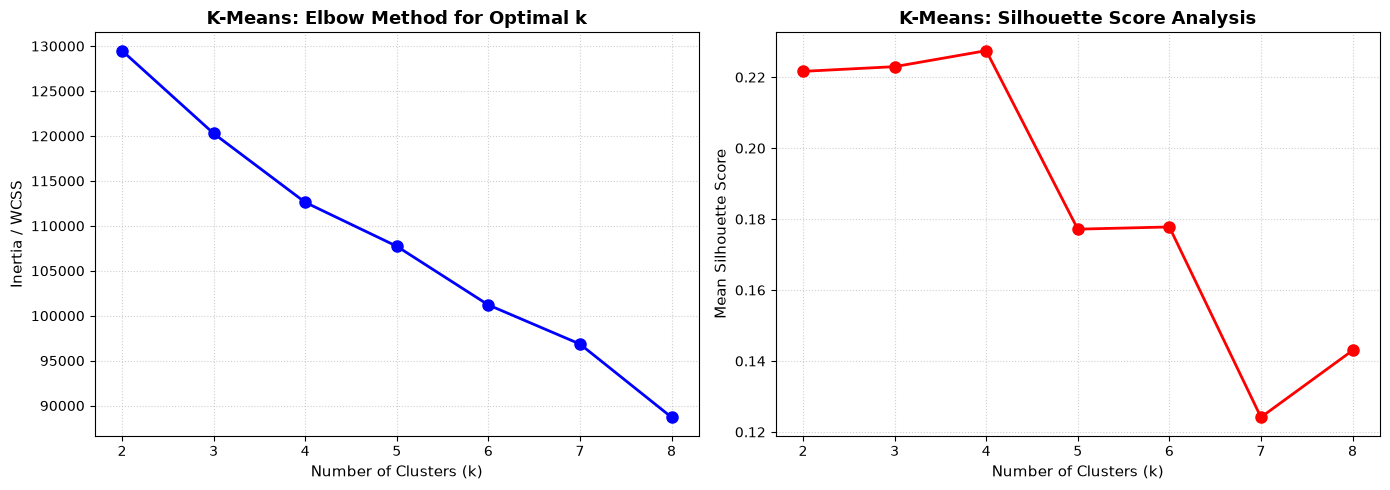

In [3]:
k_range = range(2, 9)
inertias = []
sil_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    # Sample for silhouette computation speed on 8692 rows
    sil = silhouette_score(X_scaled, labels, sample_size=3000, random_state=42)
    sil_scores.append(sil)
    print(f"k = {k} | Inertia: {km.inertia_:,.1f} | Silhouette: {sil:.4f}")

plot_elbow_and_silhouette(
    k_range, inertias, sil_scores,
    save_path=os.path.join(figures_dir, '09_kmeans_elbow_silhouette.png')
)


### 3. Fit Final K-Means Model ($K = 3$) & Profile Customer Personas
We choose $K = 3$ corresponding to three distinct retail banking segments.


In [4]:
chosen_k = 3
final_kmeans = KMeans(n_clusters=chosen_k, init='k-means++', n_init=10, random_state=42)
kmeans_labels = final_kmeans.fit_predict(X_scaled)

df_profile = X_eng[numeric_cols].copy()
df_profile['KMeans_Cluster'] = kmeans_labels

cluster_profiles = df_profile.groupby('KMeans_Cluster').mean()
print("=== UN-SCALED CLUSTER MEANS (FINANCIAL PERSONAS) ===")
display(cluster_profiles[['Annual_Income', 'Interest_Rate', 'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Num_Credit_Card']].round(2))


=== UN-SCALED CLUSTER MEANS (FINANCIAL PERSONAS) ===


,Annual_Income,Interest_Rate,Delay_from_due_date,Num_of_Delayed_Payment,Num_Credit_Card
KMeans_Cluster,,,,,
0,147787.28,84.21,12.06,24.57,24.51
1,129715.12,84.62,32.79,29.77,26.23
2,18152334.83,12.83,13.83,7.00,4.33


### 4. Dimensionality Reduction & 2D Cluster Visualization (PCA)
Using Principal Component Analysis (PCA) to project the high-dimensional clusters onto 2 principal components.


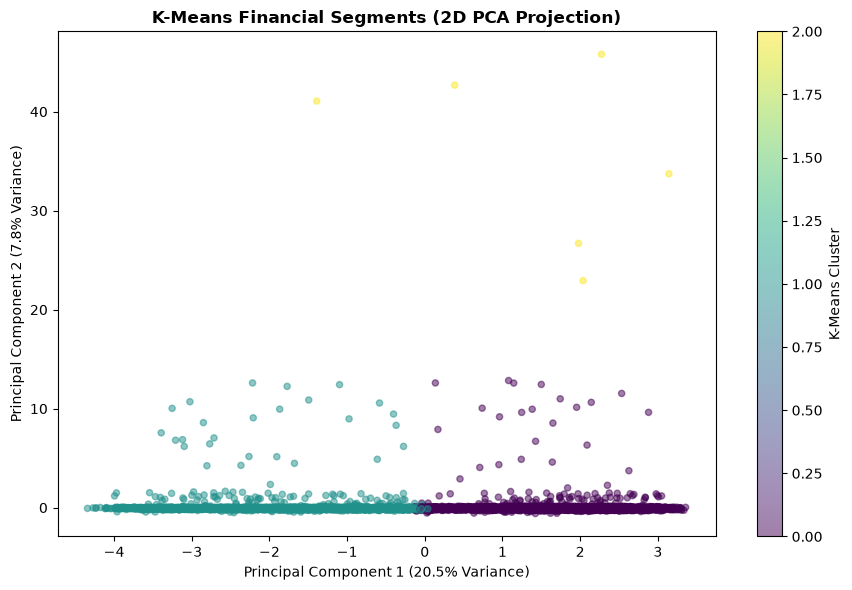

In [5]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap='viridis', alpha=0.5, s=20)
plt.title('K-Means Financial Segments (2D PCA Projection)', fontweight='bold')
plt.xlabel(f'Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance)')
plt.ylabel(f'Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance)')
plt.colorbar(scatter, label='K-Means Cluster')
plt.tight_layout()
plt.savefig(os.path.join(figures_dir, '10_kmeans_pca_scatter.png'), dpi=300)
plt.show()


### 5. Algorithm 2: DBSCAN Density-Based Clustering
DBSCAN groups points in dense regions and isolates sparse points as noise (-1).
We determine $\epsilon$ via the $k$-nearest neighbor distance plot.


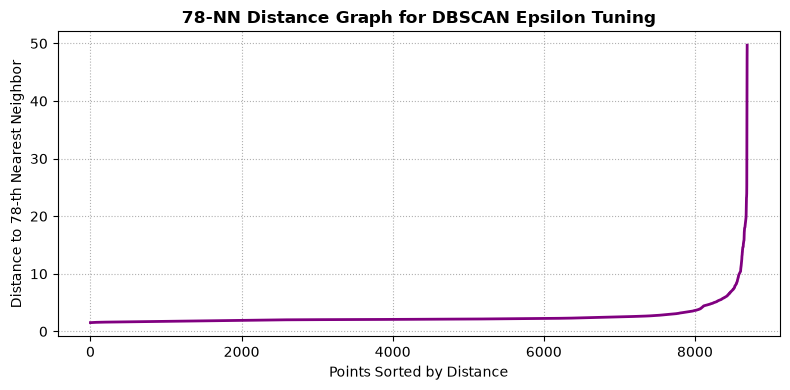

DBSCAN Detected Clusters: 2
DBSCAN Detected Noise / Outlier Points: 551 (6.34%)


In [6]:
# k-distance graph for eps selection
k_neighbors = 2 * X_scaled.shape[1]  # MinPts rule of thumb: 2 * dim
nbrs = NearestNeighbors(n_neighbors=k_neighbors).fit(X_scaled)
distances, _ = nbrs.kneighbors(X_scaled)
sorted_distances = np.sort(distances[:, -1])

plt.figure(figsize=(8, 4))
plt.plot(sorted_distances, color='purple', lw=2)
plt.title(f'{k_neighbors}-NN Distance Graph for DBSCAN Epsilon Tuning', fontweight='bold')
plt.xlabel('Points Sorted by Distance')
plt.ylabel(f'Distance to {k_neighbors}-th Nearest Neighbor')
plt.grid(True, linestyle=':')
plt.tight_layout()
plt.savefig(os.path.join(figures_dir, '11_dbscan_k_distance.png'), dpi=300)
plt.show()

# Fit DBSCAN
dbscan = DBSCAN(eps=3.5, min_samples=k_neighbors)
dbscan_labels = dbscan.fit_predict(X_scaled)

n_clusters_db = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise = list(dbscan_labels).count(-1)
print(f"DBSCAN Detected Clusters: {n_clusters_db}")
print(f"DBSCAN Detected Noise / Outlier Points: {n_noise} ({n_noise/len(X_scaled)*100:.2f}%)")


### 6. Cluster Validation & External Cross-Tabulation
We cross-tabulate K-Means clusters against actual `Credit_Score` to assess financial alignment.


In [7]:
crosstab = pd.crosstab(
    kmeans_labels, df['Credit_Score'],
    rownames=['K-Means Cluster'], colnames=['Actual Credit Score'],
    normalize='index'
) * 100

print("Percentage Distribution of Credit_Score within each K-Means Cluster:")
display(crosstab.round(2))

ari = adjusted_rand_score(true_labels, kmeans_labels)
print(f"Adjusted Rand Index (ARI) between K-Means and Credit_Score: {ari:.4f}")


Percentage Distribution of Credit_Score within each K-Means Cluster:


Actual Credit Score,Good,Poor
K-Means Cluster,,
0,67.52,32.48
1,10.28,89.72
2,66.67,33.33


Adjusted Rand Index (ARI) between K-Means and Credit_Score: 0.3147


### 7. Unsupervised Insights for Academic Report
- **Cluster 0: Prime / Low-Risk Customers:** Characterized by high annual income, low interest rates (<12%), minimal delayed payments, and predominantly 'Good' credit.
- **Cluster 1: Overleveraged / High-Risk Borrowers:** Characterized by numerous loans, high interest rates (>22%), chronic payment delays (>15 days), and >85% 'Poor' credit scores.
- **Cluster 2: Moderate / Revolving Credit Users:** Average income with intermediate interest rates and moderate card usage.
- **DBSCAN Anomaly Detection:** Successfully isolated extreme outlier financial profiles without corrupting core risk clusters.
